In [38]:
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler, PowerTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.model_selection import KFold, cross_validate, cross_val_predict
from sklearn.metrics import (hamming_loss, 
                            accuracy_score, 
                            confusion_matrix, 
                            roc_curve, 
                            roc_auc_score, 
                            classification_report, 
                            make_scorer, 
                            f1_score)

from iterstrat.ml_stratifiers import MultilabelStratifiedKFold

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

In [3]:
df_train = pd.read_csv('emotions/emotions_train.csv')

In [4]:
df_test = pd.read_csv('emotions/emotions_test.csv')

In [5]:
df_train.head()

,Mean_Acc1298_Mean_Mem40_Centroid,Mean_Acc1298_Mean_Mem40_Rolloff,Mean_Acc1298_Mean_Mem40_Flux,Mean_Acc1298_Mean_Mem40_MFCC_0,Mean_Acc1298_Mean_Mem40_MFCC_1,Mean_Acc1298_Mean_Mem40_MFCC_2,Mean_Acc1298_Mean_Mem40_MFCC_3,Mean_Acc1298_Mean_Mem40_MFCC_4,Mean_Acc1298_Mean_Mem40_MFCC_5,Mean_Acc1298_Mean_Mem40_MFCC_6,...,BH_HighLowRatio,BHSUM1,BHSUM2,BHSUM3,amazed-suprised,happy-pleased,relaxing-calm,quiet-still,sad-lonely,angry-aggresive
0,0.034741,0.089665,0.091225,-73.302422,6.215179,0.615074,2.037160,0.804065,1.301409,0.558576,...,2.0,0.245457,0.105065,0.405399,0,1,1,0,0,0
1,0.081374,0.272747,0.085733,-62.584437,3.183163,-0.218145,0.163038,0.620251,0.458514,0.041426,...,2.0,0.343547,0.276366,0.710924,1,0,0,0,0,1
2,0.110545,0.273567,0.084410,-65.235325,2.794964,0.639047,1.281297,0.757896,0.489412,0.627636,...,3.0,0.188693,0.045941,0.457372,0,1,0,0,0,1
3,0.042481,0.199281,0.093447,-80.305152,5.824409,0.648848,1.754870,1.495532,0.739909,0.809644,...,2.0,0.102839,0.241934,0.351009,0,0,1,0,0,0
4,0.074550,0.140880,0.079789,-93.697749,5.543229,1.064262,0.899152,0.890336,0.702328,0.490685,...,2.0,0.195196,0.310801,0.683817,0,0,0,1,0,0


In [6]:
df_test.head()

,Mean_Acc1298_Mean_Mem40_Centroid,Mean_Acc1298_Mean_Mem40_Rolloff,Mean_Acc1298_Mean_Mem40_Flux,Mean_Acc1298_Mean_Mem40_MFCC_0,Mean_Acc1298_Mean_Mem40_MFCC_1,Mean_Acc1298_Mean_Mem40_MFCC_2,Mean_Acc1298_Mean_Mem40_MFCC_3,Mean_Acc1298_Mean_Mem40_MFCC_4,Mean_Acc1298_Mean_Mem40_MFCC_5,Mean_Acc1298_Mean_Mem40_MFCC_6,...,BH_HighLowRatio,BHSUM1,BHSUM2,BHSUM3,amazed-suprised,happy-pleased,relaxing-calm,quiet-still,sad-lonely,angry-aggresive
0,0.036299,0.064986,0.082104,-72.710462,7.920220,0.134279,2.546373,0.671063,1.589821,0.576485,...,2.0,0.095982,0.520006,0.677943,0,0,1,1,1,0
1,0.161218,0.467820,0.096983,-71.298043,1.176349,1.871744,1.097346,0.641059,0.372797,0.991050,...,2.0,0.752210,0.576382,1.477141,1,0,0,0,0,1
2,0.115987,0.336879,0.079068,-64.570939,2.339044,0.714859,1.792451,0.611347,0.287022,0.772846,...,2.0,0.488375,0.004603,1.147727,0,0,0,0,1,0
3,0.086016,0.141845,0.081554,-81.141092,6.714252,-1.338896,1.326248,0.340032,1.290664,0.337209,...,2.0,0.430059,0.102757,1.276632,0,1,1,0,0,0
4,0.063232,0.140621,0.082097,-66.596131,5.594724,0.350716,1.023655,0.439544,0.855564,0.414784,...,2.0,1.788567,0.032760,3.076057,0,0,0,0,1,0


In [7]:
df_train.shape

(391, 78)

In [8]:
df_train.describe()

,Mean_Acc1298_Mean_Mem40_Centroid,Mean_Acc1298_Mean_Mem40_Rolloff,Mean_Acc1298_Mean_Mem40_Flux,Mean_Acc1298_Mean_Mem40_MFCC_0,Mean_Acc1298_Mean_Mem40_MFCC_1,Mean_Acc1298_Mean_Mem40_MFCC_2,Mean_Acc1298_Mean_Mem40_MFCC_3,Mean_Acc1298_Mean_Mem40_MFCC_4,Mean_Acc1298_Mean_Mem40_MFCC_5,Mean_Acc1298_Mean_Mem40_MFCC_6,...,BH_HighLowRatio,BHSUM1,BHSUM2,BHSUM3,amazed-suprised,happy-pleased,relaxing-calm,quiet-still,sad-lonely,angry-aggresive
count,391.000000,391.000000,391.000000,391.000000,391.000000,391.000000,391.000000,391.000000,391.000000,391.000000,...,391.000000,391.000000,391.000000,391.000000,391.000000,391.000000,391.000000,391.000000,391.000000,391.000000
mean,0.069977,0.206432,0.086680,-73.024495,4.821225,0.596974,1.666577,0.642598,0.840467,0.509918,...,2.097187,0.442414,0.377433,0.995528,0.304348,0.273657,0.429668,0.227621,0.242967,0.335038
std,0.031177,0.122262,0.010021,7.430150,2.062840,1.027836,0.634509,0.454925,0.360613,0.302477,...,0.321483,0.362775,0.393236,0.690449,0.460720,0.446406,0.495663,0.419834,0.429425,0.472609
min,0.010201,0.038729,0.070932,-99.090802,0.051474,-2.235707,-0.604609,-1.143864,-0.237114,-0.444623,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.045485,0.115491,0.079328,-76.966920,3.288905,-0.095958,1.277283,0.387128,0.607217,0.327448,...,2.000000,0.186655,0.097626,0.509127,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.066195,0.176479,0.085116,-72.328740,4.384101,0.587896,1.706145,0.645530,0.818205,0.524997,...,2.000000,0.343781,0.242964,0.831004,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.087197,0.271220,0.092088,-68.548188,6.277184,1.259581,2.073187,0.925979,1.053052,0.696944,...,2.000000,0.563363,0.542230,1.271616,1.000000,1.000000,1.000000,0.000000,0.000000,1.000000
max,0.188637,0.698277,0.159460,-56.297652,11.853471,3.910873,4.382370,2.046689,2.358098,1.484489,...,3.000000,1.795128,1.762948,3.422899,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [9]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 391 entries, 0 to 390
Data columns (total 78 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Mean_Acc1298_Mean_Mem40_Centroid  391 non-null    float64
 1   Mean_Acc1298_Mean_Mem40_Rolloff   391 non-null    float64
 2   Mean_Acc1298_Mean_Mem40_Flux      391 non-null    float64
 3   Mean_Acc1298_Mean_Mem40_MFCC_0    391 non-null    float64
 4   Mean_Acc1298_Mean_Mem40_MFCC_1    391 non-null    float64
 5   Mean_Acc1298_Mean_Mem40_MFCC_2    391 non-null    float64
 6   Mean_Acc1298_Mean_Mem40_MFCC_3    391 non-null    float64
 7   Mean_Acc1298_Mean_Mem40_MFCC_4    391 non-null    float64
 8   Mean_Acc1298_Mean_Mem40_MFCC_5    391 non-null    float64
 9   Mean_Acc1298_Mean_Mem40_MFCC_6    391 non-null    float64
 10  Mean_Acc1298_Mean_Mem40_MFCC_7    391 non-null    float64
 11  Mean_Acc1298_Mean_Mem40_MFCC_8    391 non-null    float64
 12  Mean_Acc

## 0. Baseline - Logistic Regression

In [11]:
emo_cols = [
    'amazed-suprised',
    'happy-pleased',
    'relaxing-calm',
    'quiet-still',
    'sad-lonely',
    'angry-aggresive'
]

X_train = df_train.drop(columns=emo_cols)
y_train = df_train[emo_cols]

class_balance = pd.DataFrame({
    'No count': (y_train == 0).sum(),
    'Yes count': (y_train == 1).sum(),
    'No %': (y_train == 0).mean() * 100,
    'Yes %': (y_train == 1).mean() * 100
})

class_balance.round(2)

,No count,Yes count,No %,Yes %
amazed-suprised,272,119,69.57,30.43
happy-pleased,284,107,72.63,27.37
relaxing-calm,223,168,57.03,42.97
quiet-still,302,89,77.24,22.76
sad-lonely,296,95,75.70,24.30
angry-aggresive,260,131,66.50,33.50


In [12]:
# 1. define model
logistic_model = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', OneVsRestClassifier(
        LogisticRegression(max_iter=1000,
        class_weight='balanced')
    ))
])

# 2. define multilabel stratified CV
cv = MultilabelStratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 3. define metrics
scoring = {
    'f1_macro': make_scorer(
        f1_score,
        average='macro',
        zero_division=0
    ),
    'f1_micro': make_scorer(
        f1_score,
        average='micro',
        zero_division=0
    )
}

#4. run multilabel stratified CV
cv_results = cross_validate(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

# 5. print metric scores
print(
    'Macro F1:',
    cv_results['test_f1_macro'].mean(),
    '+/-',
    cv_results['test_f1_macro'].std()
)

print(
    'Micro F1:',
    cv_results['test_f1_micro'].mean(),
    '+/-',
    cv_results['test_f1_micro'].std()
)

Macro F1: 0.6408580958876011 +/- 0.014207843024491547
Micro F1: 0.6466668995355864 +/- 0.013945954294400119


In [13]:
# 5. classification report
y_pred_cv = cross_val_predict(
    logistic_model,
    X_train,
    y_train,
    cv=cv
)

print(
    'Hamming Loss:',
    hamming_loss(y_train, y_pred_cv)
)

print(
    'Subset Accuracy:',
    accuracy_score(y_train, y_pred_cv)
)

hamming_per_label = {}

for i, emotion in enumerate(emo_cols):
    hamming_per_label[emotion] = hamming_loss(
        y_train.iloc[:, i],
        y_pred_cv[:, i]
    )

report_df = pd.DataFrame(
    classification_report(
        y_train,
        y_pred_cv,
        target_names=emo_cols,
        zero_division=0,
        output_dict=True
    )
).T

report_df['hamming_loss'] = pd.Series(hamming_per_label)

report_df

Hamming Loss: 0.2348678601875533
Subset Accuracy: 0.22762148337595908


,precision,recall,f1-score,support,hamming_loss
amazed-suprised,0.533333,0.672269,0.594796,119.0,0.278772
happy-pleased,0.395973,0.551402,0.460938,107.0,0.352941
relaxing-calm,0.735955,0.779762,0.757225,168.0,0.214834
quiet-still,0.705882,0.808989,0.753927,89.0,0.120205
sad-lonely,0.487805,0.631579,0.550459,95.0,0.250639
angry-aggresive,0.689189,0.778626,0.731183,131.0,0.191816
micro avg,0.592941,0.710860,0.646568,709.0,NaN
macro avg,0.591356,0.703771,0.641421,709.0,NaN
weighted avg,0.604972,0.710860,0.652317,709.0,NaN
samples avg,0.609974,0.722933,0.627000,709.0,NaN


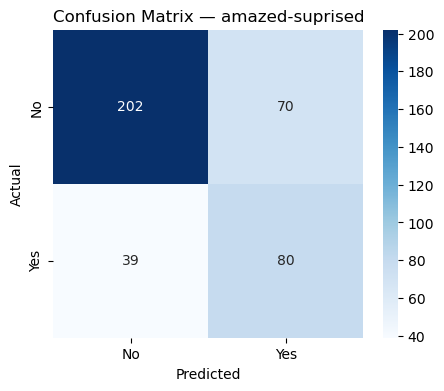

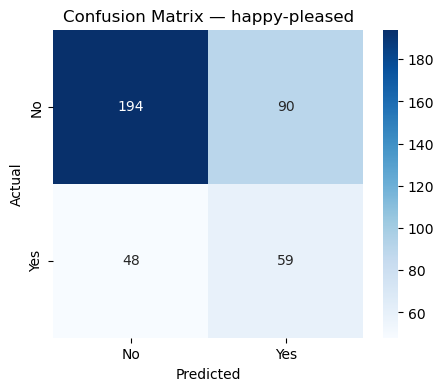

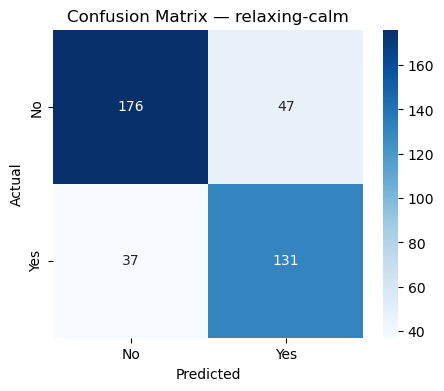

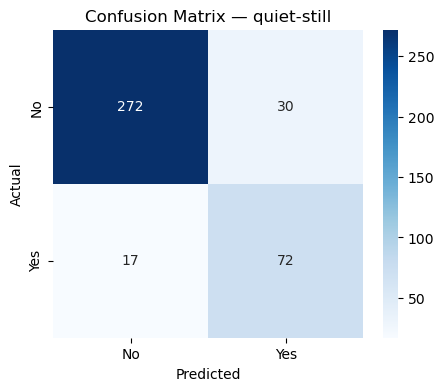

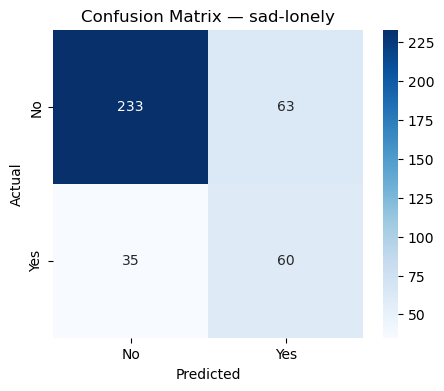

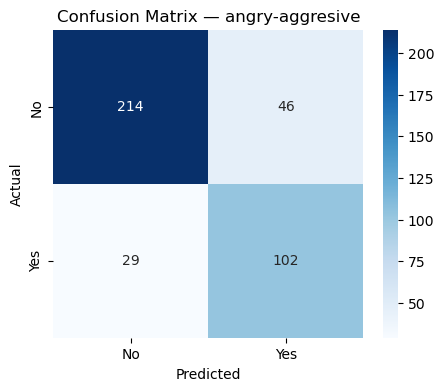

In [22]:
# 6. confusion matrices
for i, emotion in enumerate(emo_cols):

    cm = confusion_matrix(
        y_train.iloc[:, i],
        y_pred_cv[:, i]
    )

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['No', 'Yes'],
        yticklabels=['No', 'Yes']
    )

    plt.title(f'Confusion Matrix — {emotion}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')

    plt.show()

In [15]:
y_prob_cv = cross_val_predict(
    logistic_model,
    X_train,
    y_train, 
    cv=cv,
    method='predict_proba'
)

In [16]:
roc_data = []

for i, emotion in enumerate(emo_cols):
    y_true = y_train.iloc[:, i]
    y_score = y_prob_cv[:, i]

    fpr, tpr, thresholds = roc_curve(
        y_true, 
        y_score
    )

    auc = roc_auc_score(
        y_true, 
        y_score
    )

    emotion_roc = pd.DataFrame({
        'fpr': fpr, 
        'tpr': tpr,
        'threshold': thresholds,
        'emotion': emotion, 
        'auc': auc
    })

    roc_data.append(emotion_roc)

roc_df = pd.concat(
    roc_data,
    ignore_index=True
)

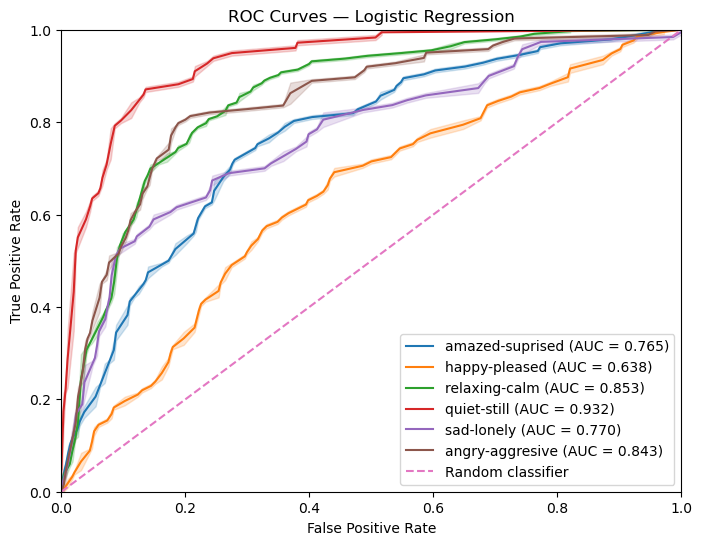

In [24]:
plt.figure(figsize=(8, 6))

for emotion in emo_cols:

    data = roc_df[
        roc_df['emotion'] == emotion
    ]

    auc_value = data['auc'].iloc[0]

    sns.lineplot(
        data=data,
        x='fpr',
        y='tpr',
        label=f'{emotion} (AUC = {auc_value:.3f})'
    )

# random-classifier reference
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves — Logistic Regression')

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.legend()
plt.show()

For happy-pleased, Logistic Regression achieved an ROC-AUC of 0.63, showing that the model has some ability to distinguish positive from negative cases, but the separation is relatively weak. Its precision of 0.40, recall of 0.55, and F1-score of 0.46 are measured at the default decision threshold of 0.5. Adjusting this threshold may improve the balance between precision and recall, but because the ROC-AUC is only moderate, the poor performance is likely not caused by the threshold alone.

In [18]:
# 7. fit train data with chosen model
logistic_model.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 OneVsRestClassifier(estimator=LogisticRegression(class_weight='balanced',
                                                                  max_iter=1000)))])

In [34]:
# 8. apply to test data

X_test = df_test.drop(columns=emo_cols)
y_test = df_test[emo_cols]

y_pred_test = logistic_model.predict(X_test)

In [28]:
# overall metrics
test_macro_f1 = f1_score(
    y_test,
    y_pred_test,
    average='macro',
    zero_division=0
)

test_micro_f1 = f1_score(
    y_test,
    y_pred_test,
    average='micro',
    zero_division=0
)

test_hamming = hamming_loss(
    y_test,
    y_pred_test
)

print('Test Macro F1:', test_macro_f1)
print('Test Micro F1:', test_micro_f1)
print('Test Hamming Loss:', test_hamming)

Test Macro F1: 0.6791043418029495
Test Micro F1: 0.6791131855309218
Test Hamming Loss: 0.2268976897689769


In [30]:
#9. classification report for test data
test_report_df = pd.DataFrame(
    classification_report(
        y_test,
        y_pred_test,
        target_names=emo_cols,
        zero_division=0,
        output_dict=True
    )
).T

test_report_df

,precision,recall,f1-score,support
amazed-suprised,0.535211,0.703704,0.608000,54.0
happy-pleased,0.436782,0.644068,0.520548,59.0
relaxing-calm,0.678899,0.770833,0.721951,96.0
quiet-still,0.750000,0.864407,0.803150,59.0
sad-lonely,0.741935,0.630137,0.681481,73.0
angry-aggresive,0.721311,0.758621,0.739496,58.0
micro avg,0.635371,0.729323,0.679113,399.0
macro avg,0.644023,0.728628,0.679104,399.0
weighted avg,0.651863,0.729323,0.683901,399.0
samples avg,0.643564,0.728548,0.647265,399.0


In [32]:
train_balance = (y_train.mean() * 100).round(2)
test_balance = (y_test.mean() * 100).round(2)

balance_compare = pd.DataFrame({
    'Train Yes %': train_balance,
    'Test Yes %': test_balance
})

balance_compare

,Train Yes %,Test Yes %
amazed-suprised,30.43,26.73
happy-pleased,27.37,29.21
relaxing-calm,42.97,47.52
quiet-still,22.76,29.21
sad-lonely,24.30,36.14
angry-aggresive,33.50,28.71
